## **PRAKTIKUM PENGOLAHAN CITRA DIGITAL**
## *Implementasi Canny Edge Detection*

**Disusun oleh:**
- Nama: Shela Rahma Fitri
- NIM: 24260012
- Program Studi: teknik informatika
- Semester: 5

---

### Metode yang Digunakan
Canny Edge Detection merupakan metode deteksi tepi yang digunakan untuk menemukan batas objek pada citra digital berdasarkan perubahan intensitas piksel. Metode ini dilakukan melalui beberapa tahapan pengolahan citra untuk menghasilkan tepi objek yang lebih jelas.

### **Pendahuluan**

Pengolahan citra digital merupakan proses pengolahan gambar menggunakan komputer untuk memperoleh informasi tertentu dari suatu citra. Salah satu teknik dalam pengolahan citra digital adalah deteksi tepi (*Edge Detection*), yaitu teknik yang digunakan untuk menemukan batas objek berdasarkan perubahan intensitas piksel pada citra.

Deteksi tepi termasuk dalam operasi area (*Neighborhood Operation/Filtering*), karena proses pengolahan dapat memanfaatkan informasi dari piksel-piksel yang berada di sekitar suatu piksel. Teknik ini dapat membantu memperjelas kontur dan bentuk objek sehingga informasi pada citra lebih mudah dianalisis.

Salah satu metode deteksi tepi adalah Canny Edge Detection. Metode ini memiliki beberapa tahapan, yaitu penghalusan citra menggunakan Gaussian Filter, perhitungan gradien, *Non-Maximum Suppression*, penerapan ambang ganda (*Double Threshold*), dan pelacakan tepi menggunakan *Edge Tracking by Hysteresis*.

Pada praktikum ini, metode Canny Edge Detection diterapkan pada citra foto pantai untuk mendeteksi tepi objek yang terdapat di dalam gambar. Hasil pengolahan kemudian diamati untuk mengetahui kemampuan metode Canny dalam menampilkan batas dan kontur objek pada citra.

### **Tujuan Praktikum**

1. Memahami konsep dasar deteksi tepi (*Edge Detection*) dalam pengolahan citra digital.
2. Memahami tahapan kerja metode Canny Edge Detection.
3. Mengimplementasikan metode Canny Edge Detection menggunakan Python dan OpenCV.
4. Mengamati dan menganalisis hasil deteksi tepi pada citra foto pantai.

### **1. import library**

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


### **2. Membaca dan Menampilkan Citra Asli**

In [8]:
# Membaca citra dari folder foto
image = cv2.imread("foto/fotoPantai.jpg")

# Memeriksa apakah citra berhasil dibaca
if image is None:
    raise FileNotFoundError(
        "Citra tidak ditemukan. Periksa nama file dan lokasi foto."
    )

# Mengambil informasi citra
tinggi, lebar, kanal = image.shape

print("Citra berhasil dibaca!")
print("Dimensi citra :", lebar, "x", tinggi, "piksel")
print("Jumlah kanal  :", kanal)
print("Tipe data     :", image.dtype)
print("Nilai minimum :", np.min(image))
print("Nilai maksimum:", np.max(image))
print("Jumlah piksel :", tinggi * lebar)

Citra berhasil dibaca!
Dimensi citra : 960 x 1280 piksel
Jumlah kanal  : 3
Tipe data     : uint8
Nilai minimum : 0
Nilai maksimum: 255
Jumlah piksel : 1228800


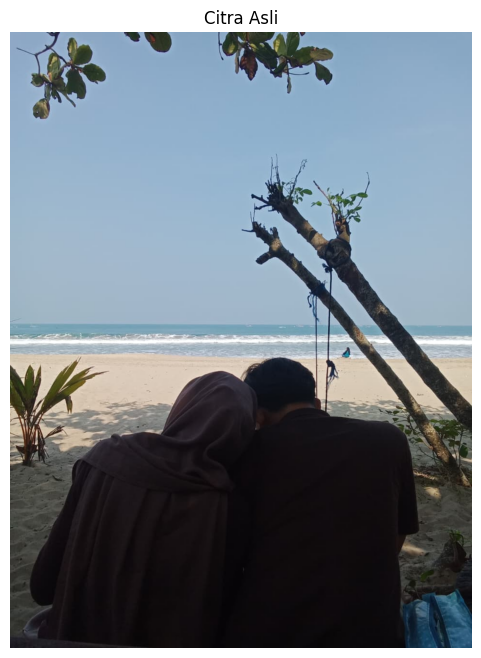

In [9]:
# Mengubah format warna BGR menjadi RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Menampilkan citra asli
plt.figure(figsize=(7, 8))
plt.imshow(image_rgb)
plt.title("Citra Asli")
plt.axis("off")
plt.show()

### **3. Konversi Citra ke Grayscale**

Citra asli memiliki tiga kanal warna, yaitu merah, hijau, dan biru (RGB). Pada tahap ini, citra diubah menjadi grayscale atau citra keabuan agar setiap piksel direpresentasikan oleh satu nilai intensitas.

Konversi grayscale dilakukan sebagai tahap persiapan sebelum proses Canny Edge Detection. Dengan menggunakan citra grayscale, perubahan intensitas antara piksel yang berdekatan dapat dianalisis untuk membantu menemukan tepi objek.

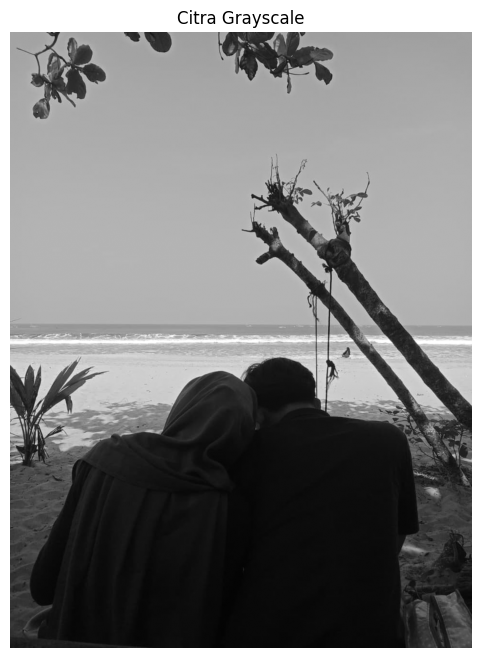

Dimensi citra grayscale: (1280, 960)
Tipe data: uint8
Nilai minimum: 1
Nilai maksimum: 255


In [10]:
# Mengubah citra berwarna menjadi grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Menampilkan citra grayscale
plt.figure(figsize=(7, 8))
plt.imshow(gray, cmap="gray")
plt.title("Citra Grayscale")
plt.axis("off")
plt.show()

# Menampilkan informasi citra grayscale
print("Dimensi citra grayscale:", gray.shape)
print("Tipe data:", gray.dtype)
print("Nilai minimum:", np.min(gray))
print("Nilai maksimum:", np.max(gray))

### **4. Penghalusan Citra Menggunakan Gaussian Filter**

Gaussian Filter merupakan proses penghalusan citra yang digunakan untuk mengurangi noise atau gangguan kecil pada gambar. Proses ini dilakukan sebelum deteksi tepi agar perubahan intensitas yang tidak diperlukan tidak terlalu memengaruhi hasil deteksi.

Gaussian Filter bekerja dengan memberikan bobot pada piksel di sekitar piksel yang sedang diproses. Piksel yang lebih dekat umumnya memiliki bobot lebih besar dibandingkan piksel yang lebih jauh.

Pada praktikum ini, Gaussian Filter diterapkan pada citra grayscale sebagai salah satu tahap persiapan dalam metode Canny Edge Detection.

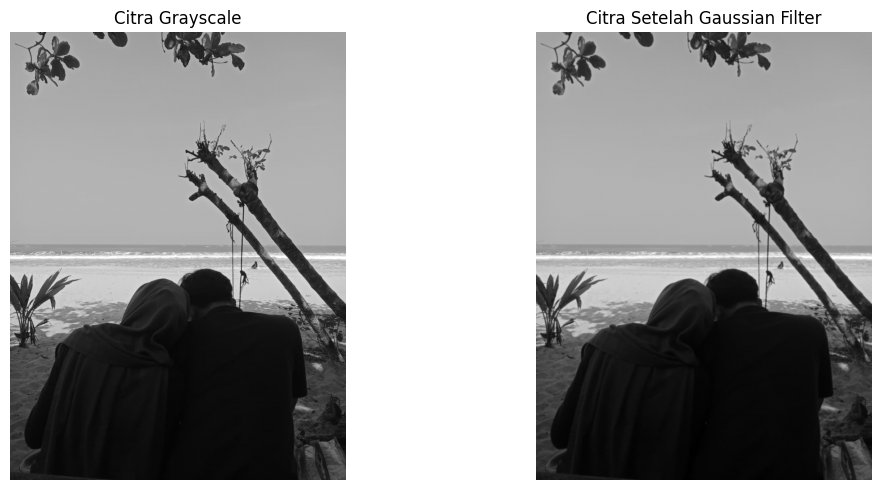

In [11]:
# Menghaluskan citra grayscale menggunakan Gaussian Filter
blur = cv2.GaussianBlur(gray, (5, 5), 1.0)

# Menampilkan perbandingan citra sebelum dan sesudah penghalusan
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Citra Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blur, cmap="gray")
plt.title("Citra Setelah Gaussian Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

### **5. Ilustrasi Perubahan Intensitas Piksel**

Untuk memahami bagaimana perubahan intensitas dapat menunjukkan tepi, kita mengambil dua contoh langsung dari foto yang digunakan dalam praktikum. Contoh pertama berasal dari area yang intensitasnya relatif stabil, sedangkan contoh kedua berasal dari area dengan perubahan intensitas yang kuat.

Visualisasi dan grafik di bawah menggunakan citra grayscale yang telah melewati Gaussian Filter. Nilai piksel ditampilkan apa adanya pada skala 0–255; tidak ada kontras buatan yang diterapkan pada nilai tersebut.

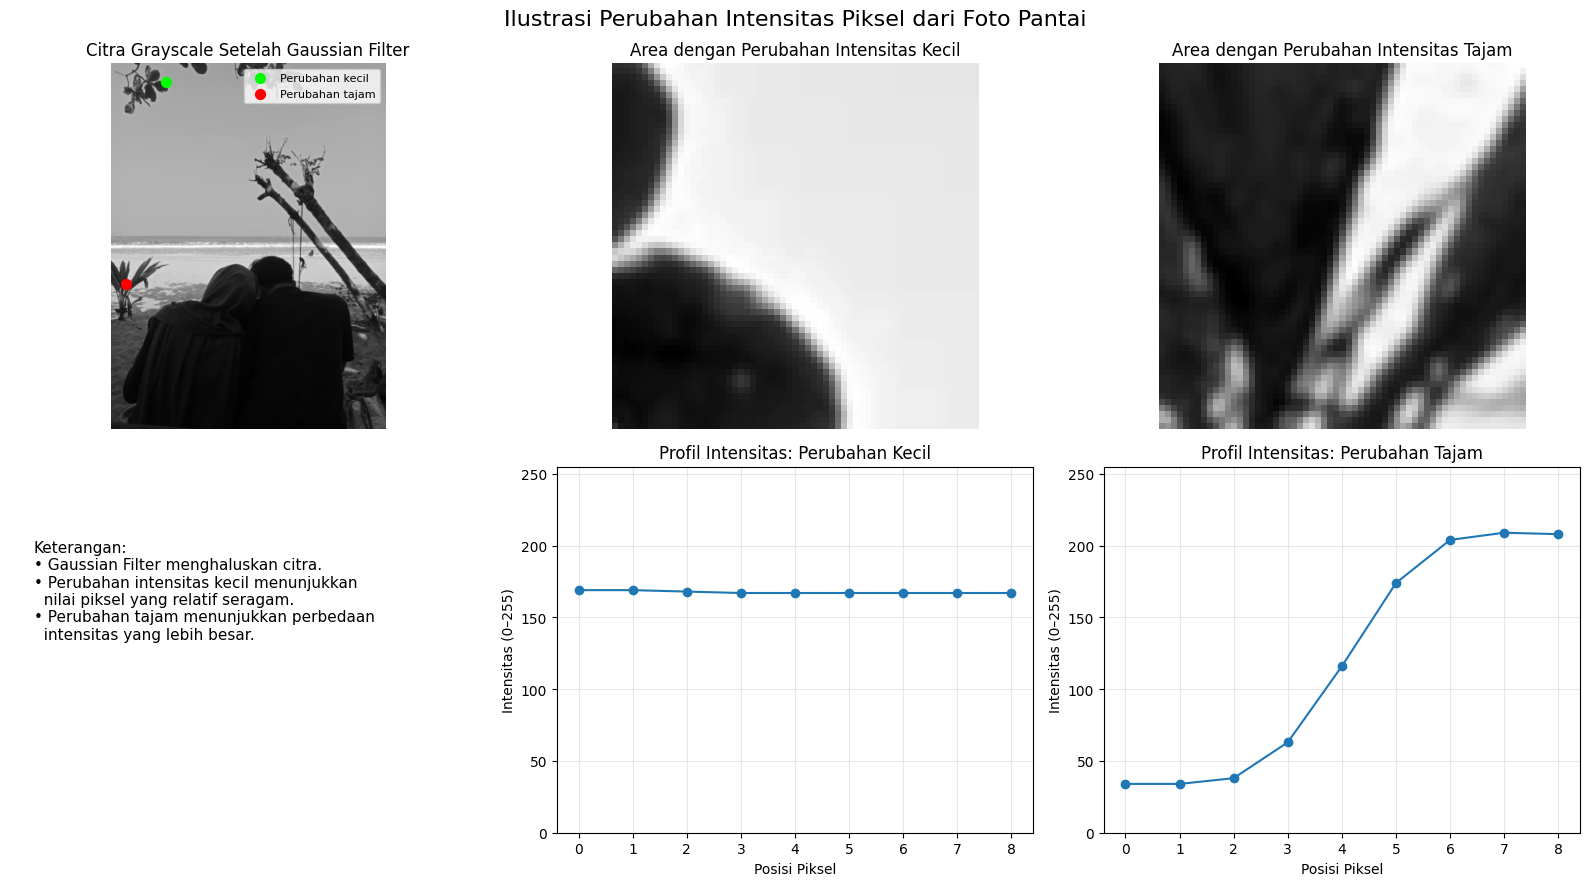

ILUSTRASI PERUBAHAN INTENSITAS PIKSEL
Titik perubahan kecil : (191, 64)
Nilai intensitas      : [169, 169, 168, 167, 167, 167, 167, 167, 167]

Titik perubahan tajam : (51, 770)
Nilai intensitas      : [34, 34, 38, 63, 116, 174, 204, 209, 208]


In [12]:
# Ilustrasi Perubahan Intensitas dari Foto Sendiri Setelah Gaussian Filter

# Pastikan citra grayscale (gray) sudah dibuat pada bagian sebelumnya.
gray_smooth = cv2.GaussianBlur(gray, (5, 5), 0)

# 1. Menghitung perubahan intensitas piksel untuk memilih contoh dari foto.
gray_float = gray_smooth.astype(np.float32)

# Menghitung gradien menggunakan operator Sobel.
gx = cv2.Sobel(gray_float, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(gray_float, cv2.CV_32F, 0, 1, ksize=3)
grad = np.hypot(gx, gy)

# Menghindari area tepi gambar saat memilih titik.
margin_y = max(1, int(gray.shape[0] * 0.05))
margin_x = max(1, int(gray.shape[1] * 0.05))

area_grad = grad[
    margin_y:gray.shape[0] - margin_y,
    margin_x:gray.shape[1] - margin_x
]

# Memilih titik dengan perubahan intensitas kecil dan besar.
y_kecil_rel, x_kecil_rel = np.unravel_index(
    np.argmin(area_grad), area_grad.shape
)
y_tajam_rel, x_tajam_rel = np.unravel_index(
    np.argmax(area_grad), area_grad.shape
)

y_kecil = int(y_kecil_rel + margin_y)
x_kecil = int(x_kecil_rel + margin_x)
y_tajam = int(y_tajam_rel + margin_y)
x_tajam = int(x_tajam_rel + margin_x)

titik_kecil = (x_kecil, y_kecil)
titik_tajam = (x_tajam, y_tajam)


# 2. Mengambil nilai intensitas piksel di sekitar titik terpilih.
def ambil_profil(gray_img, gx_img, gy_img, x, y, panjang=9):
    horizontal = abs(gx_img[y, x]) >= abs(gy_img[y, x])
    setengah = panjang // 2

    if horizontal:
        awal = max(0, min(x - setengah, gray_img.shape[1] - panjang))
        nilai = gray_img[y, awal:awal + panjang]
    else:
        awal = max(0, min(y - setengah, gray_img.shape[0] - panjang))
        nilai = gray_img[awal:awal + panjang, x]

    return nilai.astype(int)


nilai_kecil = ambil_profil(gray_smooth, gx, gy, x_kecil, y_kecil)
nilai_tajam = ambil_profil(gray_smooth, gx, gy, x_tajam, y_tajam)


# 3. Menampilkan gambar dan grafik perubahan intensitas.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle(
    "Ilustrasi Perubahan Intensitas Piksel dari Foto Pantai",
    fontsize=16,
    y=0.98
)

# Baris atas: gambar grayscale dan lokasi titik.
axes[0, 0].imshow(gray_smooth, cmap="gray")
axes[0, 0].scatter(
    [x_kecil], [y_kecil],
    color="lime", s=50, label="Perubahan kecil"
)
axes[0, 0].scatter(
    [x_tajam], [y_tajam],
    color="red", s=50, label="Perubahan tajam"
)
axes[0, 0].set_title("Citra Grayscale Setelah Gaussian Filter")
axes[0, 0].legend(fontsize=8)
axes[0, 0].axis("off")

# Menampilkan potongan area sekitar titik perubahan kecil.
ukuran_crop = 30
crop_kecil = gray_smooth[
    max(0, y_kecil - ukuran_crop):y_kecil + ukuran_crop + 1,
    max(0, x_kecil - ukuran_crop):x_kecil + ukuran_crop + 1
]
axes[0, 1].imshow(crop_kecil, cmap="gray")
axes[0, 1].set_title("Area dengan Perubahan Intensitas Kecil")
axes[0, 1].axis("off")

# Menampilkan potongan area sekitar titik perubahan tajam.
crop_tajam = gray_smooth[
    max(0, y_tajam - ukuran_crop):y_tajam + ukuran_crop + 1,
    max(0, x_tajam - ukuran_crop):x_tajam + ukuran_crop + 1
]
axes[0, 2].imshow(crop_tajam, cmap="gray")
axes[0, 2].set_title("Area dengan Perubahan Intensitas Tajam")
axes[0, 2].axis("off")

# Baris bawah: grafik nilai intensitas piksel.
axes[1, 0].axis("off")
axes[1, 0].text(
    0.05, 0.8,
    "Keterangan:\n"
    "• Gaussian Filter menghaluskan citra.\n"
    "• Perubahan intensitas kecil menunjukkan\n"
    "  nilai piksel yang relatif seragam.\n"
    "• Perubahan tajam menunjukkan perbedaan\n"
    "  intensitas yang lebih besar.",
    fontsize=11,
    va="top"
)

axes[1, 1].plot(range(len(nilai_kecil)), nilai_kecil, marker="o")
axes[1, 1].set_title("Profil Intensitas: Perubahan Kecil")
axes[1, 1].set_xlabel("Posisi Piksel")
axes[1, 1].set_ylabel("Intensitas (0–255)")
axes[1, 1].set_ylim(0, 255)
axes[1, 1].grid(True, alpha=0.3)

axes[1, 2].plot(range(len(nilai_tajam)), nilai_tajam, marker="o")
axes[1, 2].set_title("Profil Intensitas: Perubahan Tajam")
axes[1, 2].set_xlabel("Posisi Piksel")
axes[1, 2].set_ylabel("Intensitas (0–255)")
axes[1, 2].set_ylim(0, 255)
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 4. Menampilkan informasi titik yang dipilih.
print("=" * 55)
print("ILUSTRASI PERUBAHAN INTENSITAS PIKSEL")
print("=" * 55)
print(f"Titik perubahan kecil : {titik_kecil}")
print(f"Nilai intensitas      : {nilai_kecil.tolist()}")
print()
print(f"Titik perubahan tajam : {titik_tajam}")
print(f"Nilai intensitas      : {nilai_tajam.tolist()}")
print("=" * 55)

### **6. Proses Deteksi Tepi Menggunakan Canny Edge Detection**

Canny Edge Detection merupakan metode deteksi tepi yang digunakan untuk menemukan batas objek berdasarkan perubahan intensitas pada citra. Metode ini memiliki beberapa tahapan, yaitu penghalusan citra, perhitungan gradien, Non-Maximum Suppression, Double Threshold, dan Edge Tracking by Hysteresis.

Pada tahap ini, metode Canny diterapkan pada citra grayscale yang telah melalui proses Gaussian Filter. Proses deteksi tepi dilakukan menggunakan fungsi `cv2.Canny()` pada OpenCV dengan menentukan nilai ambang bawah (*low threshold*) dan ambang atas (*high threshold*).

Nilai ambang digunakan untuk membantu menentukan piksel yang termasuk tepi kuat, tepi lemah, atau bukan tepi.

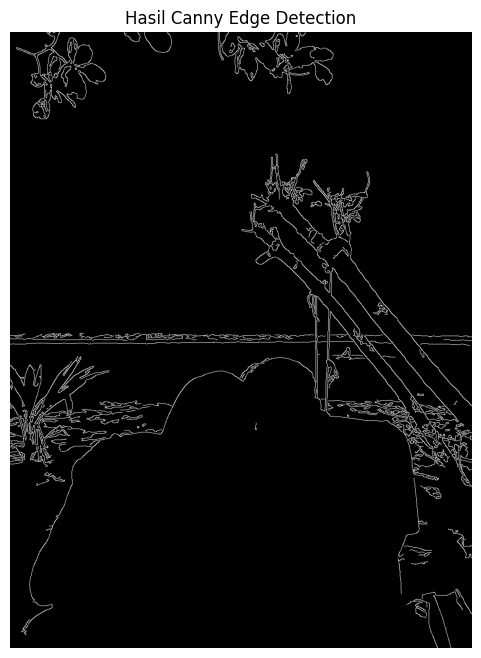

In [13]:
# Menerapkan Canny Edge Detection
low_threshold = 50
high_threshold = 150

edges = cv2.Canny(blur, low_threshold, high_threshold)

# Menampilkan hasil deteksi tepi
plt.figure(figsize=(7, 8))
plt.imshow(edges, cmap="gray")
plt.title("Hasil Canny Edge Detection")
plt.axis("off")
plt.show()

### **7. Perbandingan Citra Sebelum dan Sesudah Deteksi Tepi**

Pada tahap ini, citra asli, citra grayscale, dan hasil Canny Edge Detection ditampilkan secara berdampingan. Perbandingan ini bertujuan untuk mengamati perubahan tampilan citra setelah melalui proses konversi grayscale, penghalusan Gaussian, dan deteksi tepi.

Citra asli menampilkan objek dalam warna sebenarnya, sedangkan citra grayscale menampilkan informasi intensitas dalam bentuk keabuan. Hasil Canny menampilkan piksel-piksel yang teridentifikasi sebagai tepi sehingga batas dan kontur objek dapat diamati dengan lebih jelas.

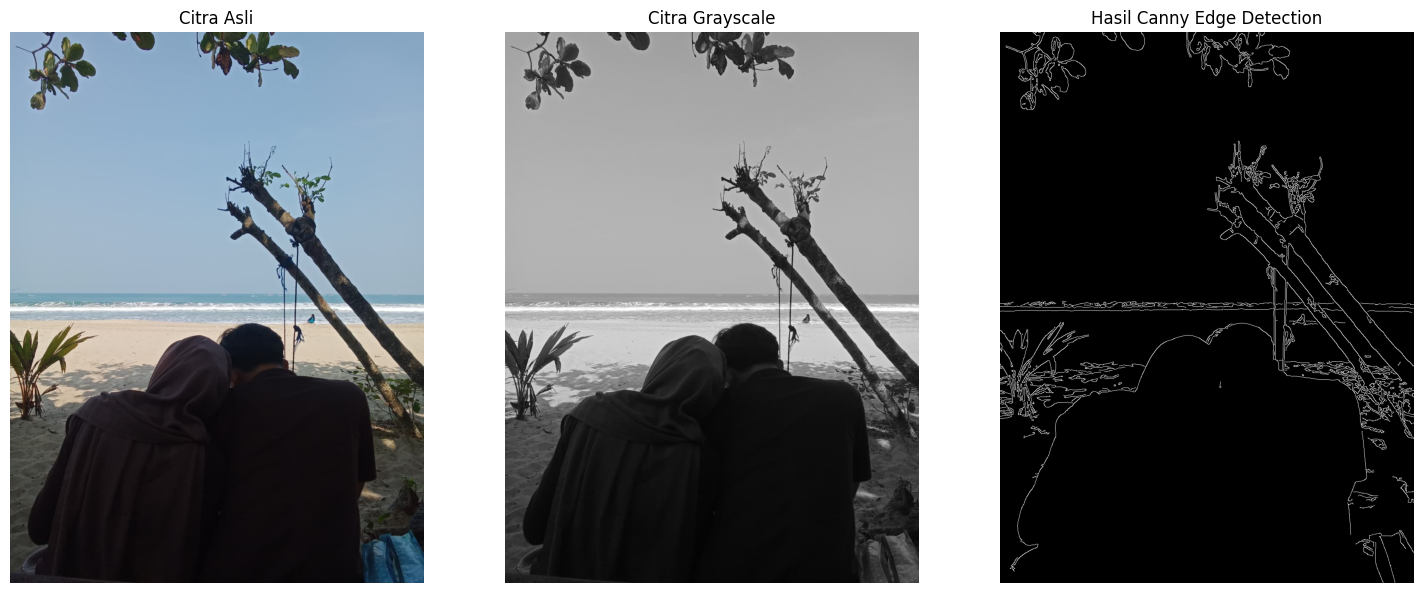

In [14]:
# Membandingkan citra asli, grayscale, dan hasil Canny
plt.figure(figsize=(15, 6))

plt.subplot(1, 3, 1)
plt.imshow(image_rgb)
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Citra Grayscale")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(edges, cmap="gray")
plt.title("Hasil Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

### **8. Analisis Kuantitatif Hasil Canny Edge Detection**

Setelah proses deteksi tepi dilakukan, hasil citra dianalisis secara kuantitatif untuk mengetahui jumlah piksel yang terdeteksi sebagai tepi dan jumlah piksel yang tidak terdeteksi sebagai tepi.

Pada citra hasil Canny, piksel tepi umumnya memiliki nilai 255 (putih), sedangkan piksel bukan tepi memiliki nilai 0 (hitam). Berdasarkan nilai tersebut, jumlah dan persentase piksel tepi dapat dihitung untuk memberikan gambaran mengenai hasil deteksi.

In [15]:
# Menghitung jumlah piksel tepi dan bukan tepi
total_piksel = edges.size
jumlah_tepi = np.count_nonzero(edges == 255)
jumlah_bukan_tepi = np.count_nonzero(edges == 0)

# Menghitung persentase piksel
persentase_tepi = (jumlah_tepi / total_piksel) * 100
persentase_bukan_tepi = (jumlah_bukan_tepi / total_piksel) * 100

# Menampilkan hasil perhitungan
print("Total piksel             :", total_piksel)
print("Jumlah piksel tepi       :", jumlah_tepi)
print("Jumlah piksel bukan tepi :", jumlah_bukan_tepi)
print("Persentase piksel tepi   :", round(persentase_tepi, 2), "%")
print("Persentase bukan tepi    :", round(persentase_bukan_tepi, 2), "%")

Total piksel             : 1228800
Jumlah piksel tepi       : 29854
Jumlah piksel bukan tepi : 1198946
Persentase piksel tepi   : 2.43 %
Persentase bukan tepi    : 97.57 %


### Rumus Perhitungan Persentase Piksel Tepi

**1. Persentase Piksel Tepi**

$$
P_{tepi} = \frac{N_{tepi}}{N_{total}} \times 100\%
$$

**2. Persentase Piksel Bukan Tepi**

$$
P_{bukan\ tepi} = \frac{N_{bukan\ tepi}}{N_{total}} \times 100\%
$$

**Keterangan:**

- P_tepi = persentase piksel yang terdeteksi sebagai tepi.
- P_bukan tepi = persentase piksel yang tidak terdeteksi sebagai tepi.
- N_tepi = jumlah piksel tepi dengan nilai intensitas 255 (putih).
- N_bukan tepi = jumlah piksel bukan tepi dengan nilai intensitas 0 (hitam).
- N_total = jumlah seluruh piksel pada citra.

**Interpretasi:**

Persentase piksel tepi menunjukkan proporsi piksel yang ditandai sebagai tepi oleh metode Canny Edge Detection. Persentase piksel bukan tepi menunjukkan proporsi piksel yang tidak ditandai sebagai tepi.

Jumlah persentase piksel tepi dan bukan tepi adalah 100%.

### **9. Analisis Hasil Deteksi Tepi**

Berdasarkan proses pengolahan citra yang telah dilakukan, metode Canny Edge Detection berhasil diterapkan pada foto pantai. Proses diawali dengan mengubah citra berwarna menjadi grayscale, kemudian melakukan penghalusan menggunakan Gaussian Filter untuk mengurangi noise sebelum deteksi tepi dilakukan.

Selanjutnya, fungsi Canny pada OpenCV digunakan untuk mendeteksi perubahan intensitas yang membentuk tepi objek. Hasilnya berupa citra biner yang menampilkan piksel tepi berwarna putih dan piksel bukan tepi berwarna hitam.

Hasil visualisasi dapat digunakan untuk mengamati batas objek pada foto pantai, seperti perbedaan antara langit dan laut, garis pantai, serta kontur objek lain yang memiliki perubahan intensitas cukup jelas. Namun, tidak semua batas objek selalu terdeteksi karena hasilnya dipengaruhi oleh kontras citra, tekstur, noise, dan nilai ambang yang digunakan.

Berdasarkan perhitungan statistik, jumlah piksel dan persentase piksel tepi memberikan gambaran kuantitatif mengenai bagian citra yang terdeteksi sebagai tepi. Nilai persentase tersebut tidak secara langsung menunjukkan tingkat akurasi metode, tetapi membantu mendeskripsikan hasil deteksi yang diperoleh.

### **10. Kesimpulan**

Berdasarkan praktikum yang telah dilakukan, dapat disimpulkan bahwa Canny Edge Detection merupakan salah satu metode pengolahan citra digital yang digunakan untuk mendeteksi batas atau tepi objek berdasarkan perubahan intensitas piksel.

Penerapan metode Canny pada foto pantai dilakukan melalui beberapa tahap, yaitu konversi citra menjadi grayscale, penghalusan citra menggunakan Gaussian Filter, dan proses deteksi tepi menggunakan fungsi `cv2.Canny()` pada OpenCV. Proses tersebut menghasilkan citra yang menampilkan piksel tepi dalam warna putih dan piksel bukan tepi dalam warna hitam.

Hasil deteksi tepi dapat membantu memperlihatkan kontur dan batas objek pada citra. Selain itu, perhitungan jumlah serta persentase piksel tepi memberikan informasi kuantitatif mengenai hasil pengolahan citra. Dengan demikian, praktikum ini membantu memahami konsep dasar dan penerapan Canny Edge Detection dalam pengolahan citra digital.
